### 1. Install YOLOv8 (Ultralytics)
Kita perlu menginstal package `ultralytics` untuk dapat menggunakan model YOLOv8.

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="apikey")
project = rf.workspace("nutrition-fact-detection").project("nutrision-fact-detection")
version = project.version(7)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 111.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.8 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to nutrision-fact-detection-7 in yolov8:: 100%|██████████| 2660/2660 [00:00<00:00, 9260.48it/s]


In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 7.9 MB/s eta 0:00:00


### 2. Mulai Training Model
Kita akan melatih model deteksi objek YOLOv8 (`yolov8n.pt` - versi nano yang cepat dan ringan) menggunakan dataset konfigurasi `data.yaml` yang didapatkan dari hasil download Roboflow sebelumnya.

In [ ]:
from ultralytics import YOLO
import os

# Memuat pre-trained model YOLOv8 (nano)
model = YOLO('yolov8n.pt')

# Menentukan path ke file data.yaml dari dataset yang diunduh
# Secara default Roboflow mengunduh ke folder proyek saat ini
data_yaml_path = os.path.join(dataset.location, 'data.yaml')

# Mulai proses training
# Anda bisa menyesuaikan jumlah epochs dan imgsz (ukuran gambar) sesuai kebutuhan
results = model.train(
    data=data_yaml_path,
    epochs=25,
    imgsz=640,
    plots=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/nutrision-fact-detection-7/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript

### 3. Evaluasi Model Setelah Training
Setelah proses training selesai, kita dapat mengevaluasi performa model menggunakan data validasi untuk melihat metrik seperti mAP (Mean Average Precision).

In [ ]:
# Menjalankan validasi pada data validasi
metrics = model.val()

# Menampilkan beberapa metrik hasil evaluasi
print(f"Mean Average Precision (mAP) 50-95: {metrics.box.map:.4f}")
print(f"mAP 50: {metrics.box.map50:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2214.6±649.6 MB/s, size: 50.5 KB)
val: Scanning /content/nutrision-fact-detection-7/valid/labels.cache... 266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 266/266 85.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 2.8it/s 6.1s
                   all        266        267      0.956      0.974       0.98      0.841
Speed: 4.7ms preprocess, 6.0ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/detect/val
Mean Average Precision (mAP) 50-95: 0.8412
mAP 50: 0.9802
Precision: 0.9563
Recall: 0.9738


### 4. Visualisasi Hasil Training dan Deteksi
Kita dapat menampilkan kurva performa (Loss, Precision, Recall) yang disimpan otomatis oleh YOLOv8 serta melakukan uji coba prediksi pada gambar baru.

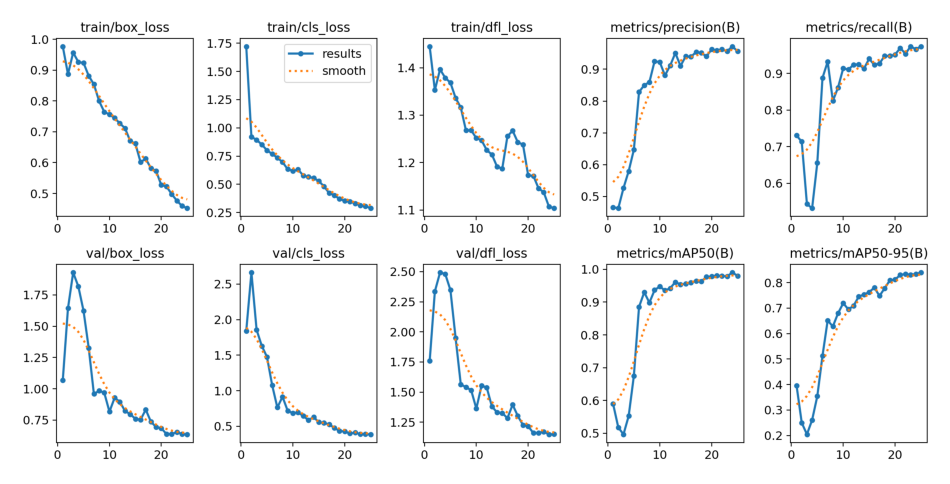

In [ ]:
import matplotlib.pyplot as plt
import cv2
import glob

# Menampilkan grafik hasil training (results.png)
results_path = 'runs/detect/train/results.png'
if os.path.exists(results_path):
    img = cv2.imread(results_path)
    plt.figure(figsize=(12, 12))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
else:
    print("File hasil visualisasi training belum tersedia. Pastikan training selesai berjalan.")


image 1/1 /content/nutrision-fact-detection-7/test/images/IMG20241113170444_jpg.rf.81b75c501990341680d35a78bbeeac91.jpg: 640x640 1 nutrition fact, 17.6ms
Speed: 1.1ms preprocess, 17.6ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 640)


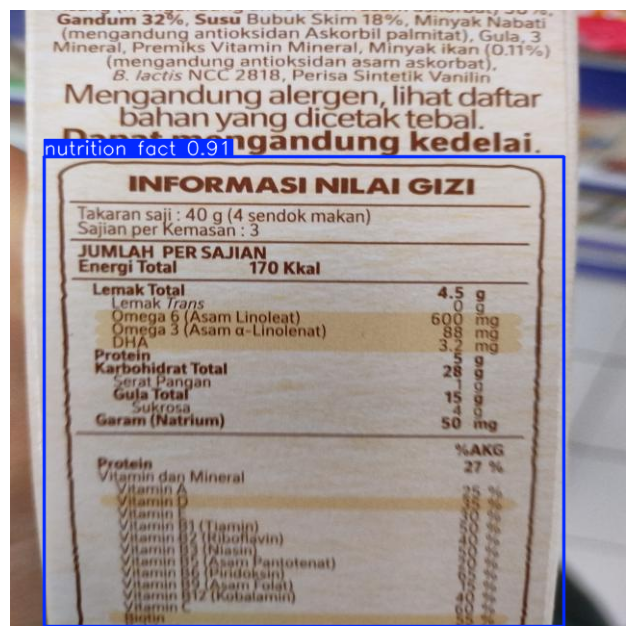

In [ ]:
# Melakukan prediksi pada salah satu gambar test untuk evaluasi kualitatif
test_images = glob.glob(os.path.join(dataset.location, 'test/images/*.jpg'))
if test_images:
    sample_img = test_images[0]
    # Jalankan inference
    pred_results = model(sample_img)

    # Tampilkan hasil prediksi
    for r in pred_results:
        im_array = r.plot()  # Menggambar bounding box hasil prediksi
        plt.figure(figsize=(8, 8))
        plt.imshow(cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()
else:
    print("Tidak ditemukan gambar pada folder test untuk divisualisasikan.")

Mengunduh model: runs/detect/train/weights/best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>